In [1]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
import matplotlib.pyplot as plt
import numpy as np

In [2]:
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=10000)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [3]:
len(x_train)

25000

In [4]:
x_train[0][:20]

[1,
 14,
 22,
 16,
 43,
 530,
 973,
 1622,
 1385,
 65,
 458,
 4468,
 66,
 3941,
 4,
 173,
 36,
 256,
 5,
 25]

In [5]:
x_train = pad_sequences(x_train, maxlen=200)
x_test = pad_sequences(x_test, maxlen=200)

In [6]:
# lstm
model = Sequential([
    tf.keras.Input(shape=(200,)),
    Embedding(input_dim=10000, output_dim=64),
    LSTM(64),
    Dense(1, activation='sigmoid')
])

In [7]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 84s 253ms/step - accuracy: 0.7549 - loss: 0.4807 - val_accuracy: 0.8368 - val_loss: 0.4529
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 251ms/step - accuracy: 0.8832 - loss: 0.2981 - val_accuracy: 0.8626 - val_loss: 0.3254
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 249ms/step - accuracy: 0.9183 - loss: 0.2170 - val_accuracy: 0.8720 - val_loss: 0.3217


In [9]:
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy)


782/782 ━━━━━━━━━━━━━━━━━━━━ 50s 64ms/step - accuracy: 0.8657 - loss: 0.3313
Test Accuracy: 0.8656799793243408


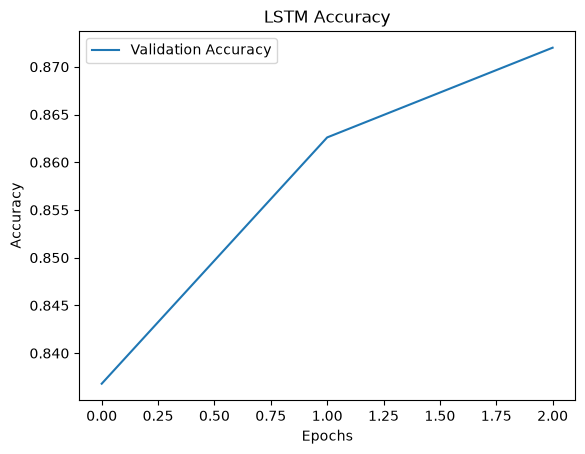

In [10]:
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('LSTM Accuracy')
plt.legend()
plt.show()

In [11]:
predictions = model.predict(x_test[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 508ms/step


In [12]:
for i in range(5):
    predicted = "Positive" if predictions[i][0] >= 0.5 else "Negative"
    actual = "Positive" if y_test[i] == 1 else "Negative"

    print(f"Review {i+1}: Predicted = {predicted}, Actual = {actual}")

Review 1: Predicted = Negative, Actual = Negative
Review 2: Predicted = Positive, Actual = Positive
Review 3: Predicted = Positive, Actual = Positive
Review 4: Predicted = Positive, Actual = Negative
Review 5: Predicted = Positive, Actual = Positive
